# 02 EDA 

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("C:/Users/Siddhesh/Downloads/bank-customer-churn/data/raw/bank_churn.csv")

df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [6]:
overall = df["Exited"].mean()

print(f"Overall Churn Rate: {overall:.2%}")

Overall Churn Rate: 20.37%


In [7]:
def churn_by(col, order=None):
    t = df.groupby(col)["Exited"].agg(
        rate="mean",
        n="size"
    ).reset_index()

    ax = sns.barplot(data=t, x=col, y="rate", order=order)
    ax.axhline(overall, ls="--", c="grey")

    for i, r in t.iterrows():
        ax.text(i, r.rate, f"n={r.n}", ha="center", va="bottom", fontsize=8)

    plt.title(f"Churn Rate by {col}")
    plt.ylabel("Churn Rate")
    plt.xlabel(col)
    plt.xticks(rotation=30)
    plt.show()

    return t

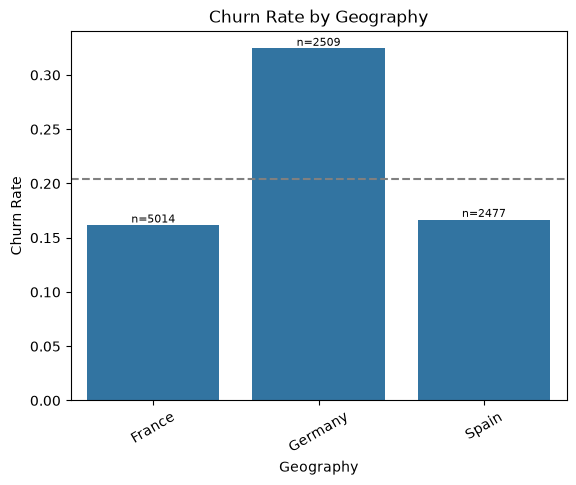

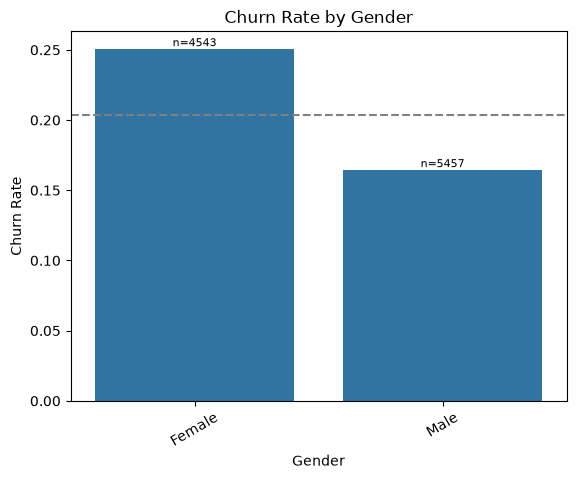

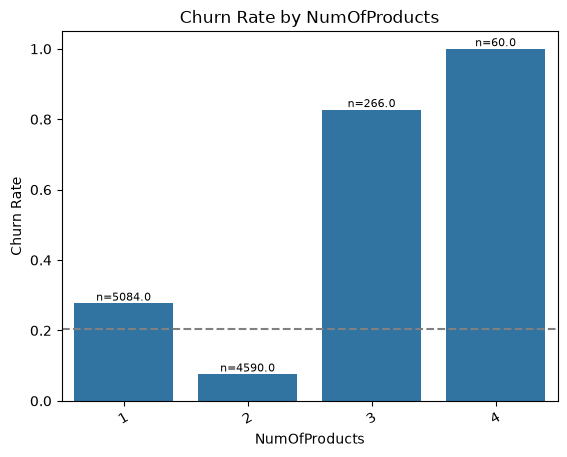

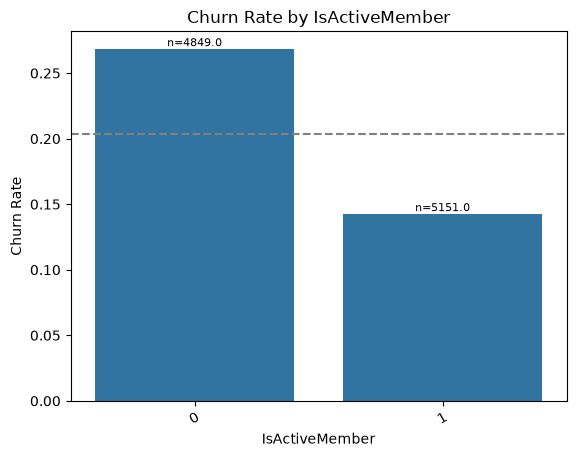

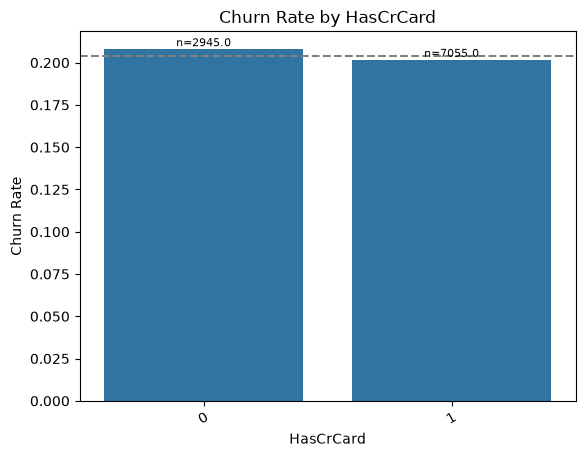

In [8]:
for c in ["Geography", "Gender", "NumOfProducts",
          "IsActiveMember", "HasCrCard"]:
    churn_by(c)

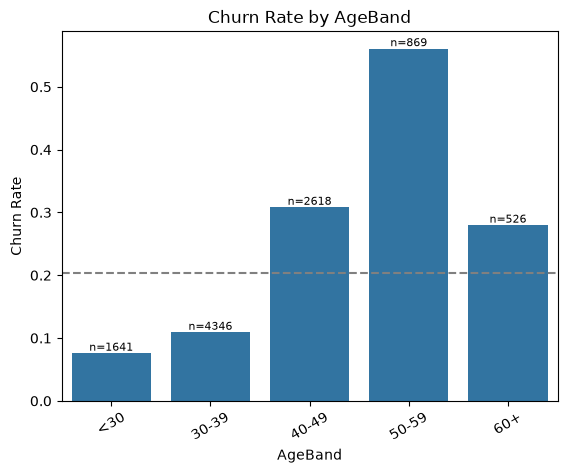

,AgeBand,rate,n
0,<30,0.075564,1641
1,30-39,0.108836,4346
2,40-49,0.307869,2618
3,50-59,0.560414,869
4,60+,0.279468,526


In [9]:
df["AgeBand"] = pd.cut(
    df["Age"],
    [0, 29, 39, 49, 59, 120],
    labels=["<30", "30-39", "40-49", "50-59", "60+"]
)

churn_by("AgeBand")

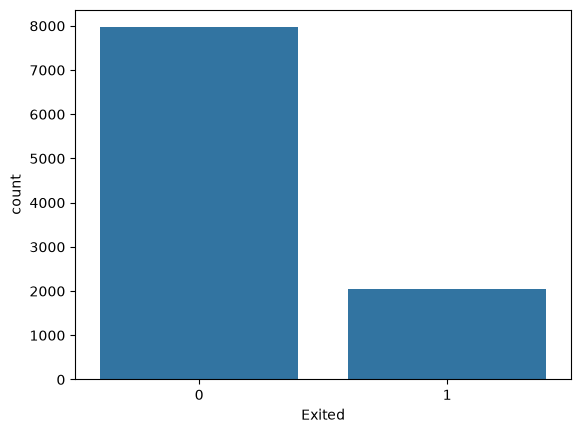

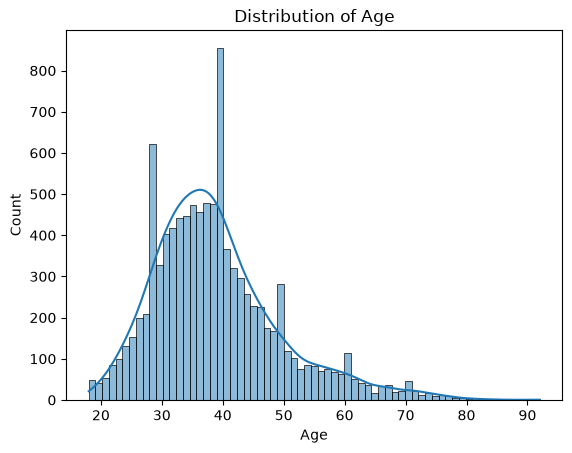

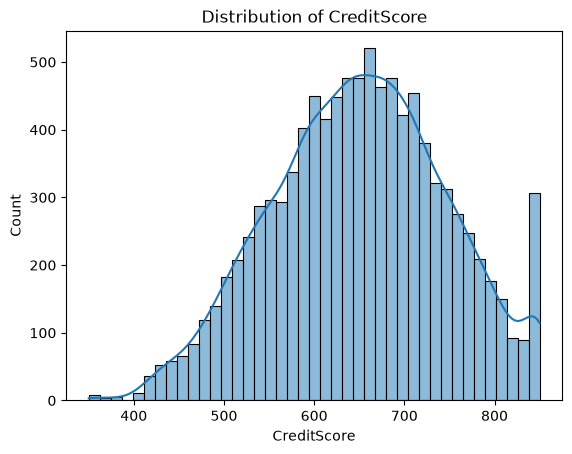

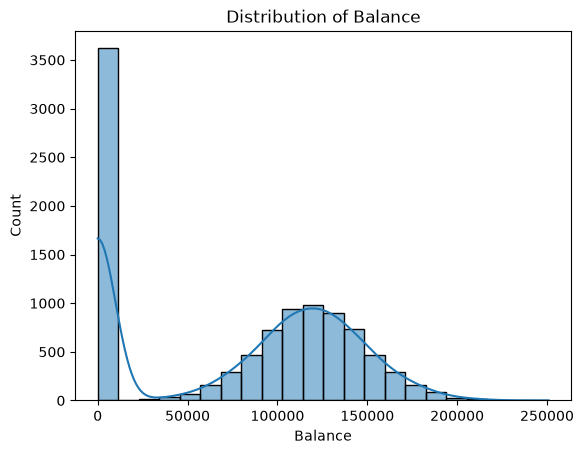

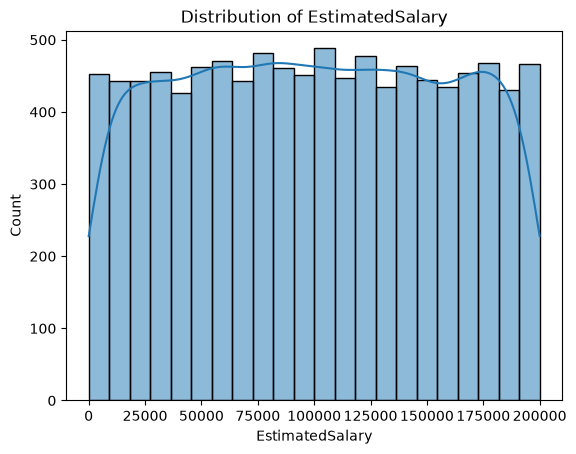

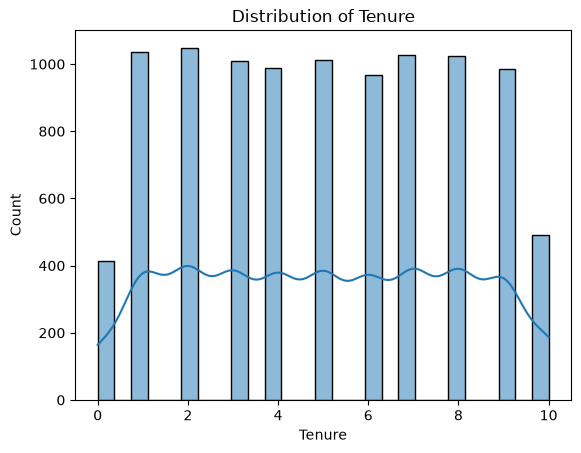

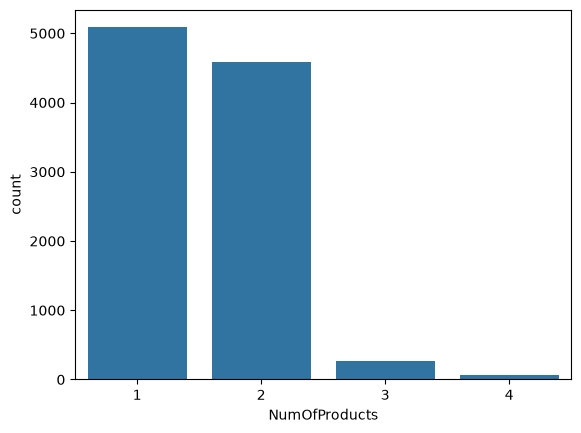

In [10]:
# Class balance
sns.countplot(data=df, x="Exited")
plt.show()

# Histograms
for col in ["Age", "CreditScore", "Balance",
            "EstimatedSalary", "Tenure"]:
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

# Product count
sns.countplot(data=df, x="NumOfProducts")
plt.show()

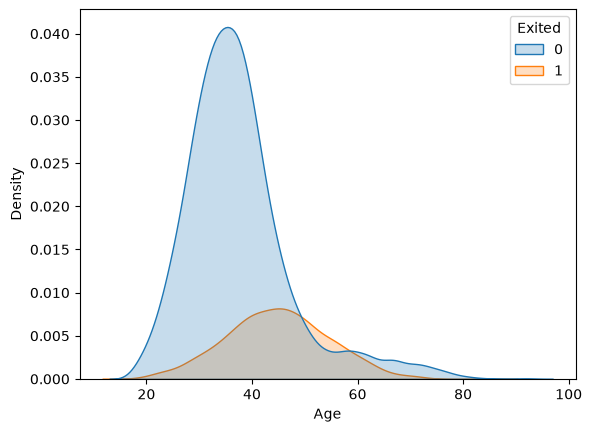

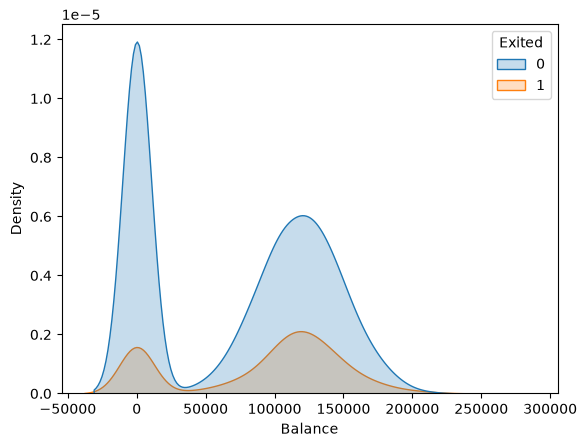

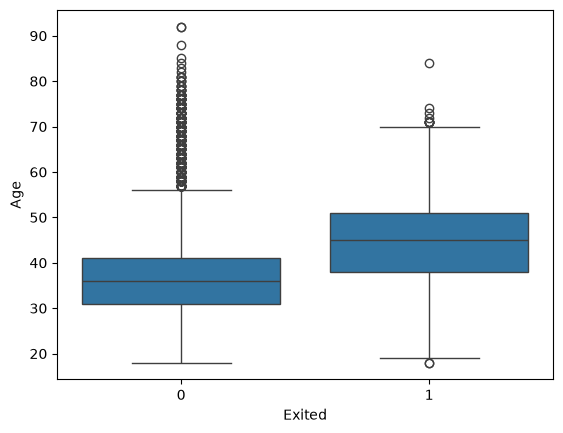

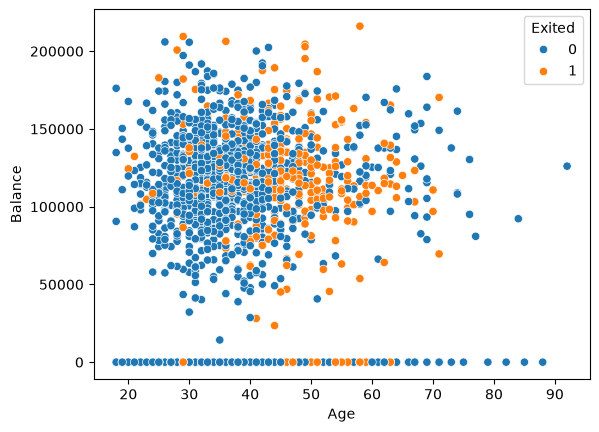

In [11]:
# Age distribution by churn
sns.kdeplot(data=df, x="Age", hue="Exited", fill=True)
plt.show()

# Balance distribution by churn
sns.kdeplot(data=df, x="Balance", hue="Exited", fill=True)
plt.show()

# Age boxplot
sns.boxplot(data=df, x="Exited", y="Age")
plt.show()

# Age vs Balance (sample for speed)
sample = df.sample(min(2000, len(df)), random_state=42)

sns.scatterplot(
    data=sample,
    x="Age",
    y="Balance",
    hue="Exited"
)
plt.show()

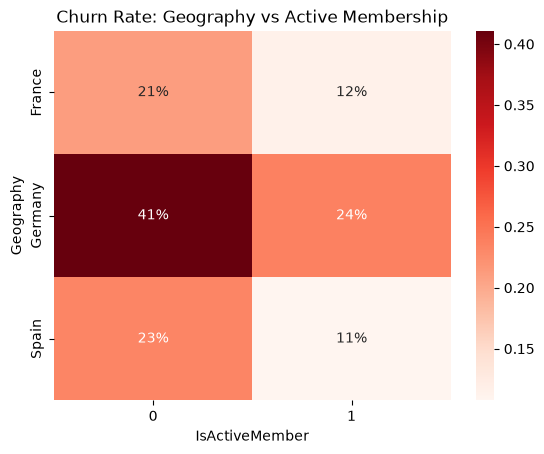

In [12]:
heatmap_data = df.pivot_table(
    index="Geography",
    columns="IsActiveMember",
    values="Exited",
    aggfunc="mean"
)

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0%",
    cmap="Reds"
)

plt.title("Churn Rate: Geography vs Active Membership")
plt.show()

In [13]:
df["BalanceGroup"] = np.where(
    df["Balance"] == 0,
    "Zero Balance",
    "Positive Balance"
)

# Churn rate and customer count
zero_balance_summary = df.groupby("BalanceGroup").agg(
    customers=("Exited", "size"),
    churn_rate=("Exited", "mean")
).reset_index()

print(zero_balance_summary)

       BalanceGroup  customers  churn_rate
0  Positive Balance       6383    0.240796
1      Zero Balance       3617    0.138236


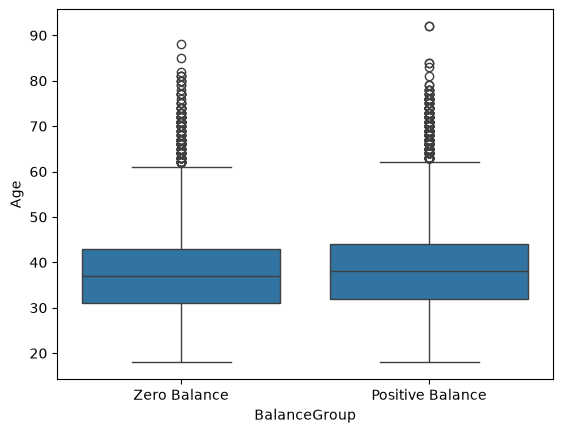

In [14]:
sns.boxplot(
    data=df,
    x="BalanceGroup",
    y="Age"
)
plt.show()